# Assignment 3: Network Traffic Analysis

**Course:** Network Systems and Security  

**Name:** Keeratpreet Singh

**Entry No.:** 2025JCS2505

## Objective
The goal of this assignment is to analyze network traffic logs provided in CSV format and extract useful traffic statistics, detect anomalies, apply memory-efficient traffic estimation methods, and identify possible security threats.

In [ ]:
from pathlib import Path

try:
    from google.colab import drive
    drive.mount('/content/drive')
except Exception:
    pass


def resolve_base_dir():
    candidates = [
        Path('/content/drive/MyDrive/NSS_A3'),
        Path('/content/drive/MyDrive'),
        Path('/content'),
        Path.cwd().resolve(),
        Path.cwd().resolve().parent,
    ]

    for candidate in candidates:
        if candidate.is_file():
            candidate = candidate.parent

        if (candidate / 'network_analysis_data1.csv').exists():
            return candidate

        matches = list(candidate.rglob('network_analysis_data1.csv')) if candidate.exists() else []
        if matches:
            return matches[0].parent

    raise FileNotFoundError(
        "Could not locate the folder containing network_analysis_data1.csv. "
        "Please check where your assignment files are stored in Google Drive."
    )


BASE_DIR = resolve_base_dir()
print("Using base directory:", BASE_DIR)


Mounted at /content/drive
Using base directory: /content/drive/MyDrive/NSS_A3


In [ ]:
import os
import glob
import math
import hashlib
import re

import numpy as np
import pandas as pd

In [ ]:
csv_files = sorted(glob.glob(str(BASE_DIR / 'network_analysis_data*.csv')))
print('CSV files found:', len(csv_files))
for file in csv_files:
    print(file)

CSV files found: 6
/content/drive/MyDrive/NSS_A3/network_analysis_data1.csv
/content/drive/MyDrive/NSS_A3/network_analysis_data2.csv
/content/drive/MyDrive/NSS_A3/network_analysis_data3.csv
/content/drive/MyDrive/NSS_A3/network_analysis_data4.csv
/content/drive/MyDrive/NSS_A3/network_analysis_data5.csv
/content/drive/MyDrive/NSS_A3/network_analysis_data6.csv


## Import all the CSV files

In [ ]:
# load and combine all csv files
# note: this notebook uses pandas for interactive analysis, even though the assignment
# also asks for sublinear techniques later in Part 2.
df_list = [pd.read_csv(file) for file in csv_files]
df = pd.concat(df_list, ignore_index=True)

print('Combined dataset shape:', df.shape)

Combined dataset shape: (2071657, 21)


In [ ]:
df.head()

,generated,appName,totalSourceBytes,totalDestinationBytes,totalDestinationPackets,totalSourcePackets,sourcePayloadAsBase64,sourcePayloadAsUTF,destinationPayloadAsBase64,destinationPayloadAsUTF,...,sourceTCPFlagsDescription,destinationTCPFlagsDescription,source,protocolName,sourcePort,destination,destinationPort,startDateTime,stopDateTime,Label
0,3/11/2014 18:21,Unknown_UDP,16076,0,0,178,NaN,NaN,NaN,NaN,...,NaN,NaN,192.168.5.122,udp_ip,5353,224.0.0.251,5353,6/13/2010 23:57,6/14/2010 0:11,Normal
1,3/11/2014 18:21,HTTPImageTransfer,384,0,0,6,NaN,NaN,NaN,NaN,...,"F,A",NaN,192.168.2.111,tcp_ip,4435,206.217.198.186,80,6/13/2010 23:58,6/14/2010 0:01,Normal
2,3/11/2014 18:21,DNS,171,642,4,2,NaN,NaN,NaN,NaN,...,NaN,NaN,192.168.4.119,udp_ip,4428,192.168.5.122,53,6/13/2010 23:58,6/13/2010 23:59,Normal
3,3/11/2014 18:21,HTTPImageTransfer,384,0,0,6,NaN,NaN,NaN,NaN,...,"F,A",NaN,192.168.4.119,tcp_ip,3639,219.94.203.105,80,6/13/2010 23:58,6/14/2010 0:00,Normal
4,3/11/2014 18:21,HTTPImageTransfer,186,128,2,2,NaN,NaN,NaN,NaN,...,"F,P,A",R,192.168.4.119,tcp_ip,3641,98.137.80.50,80,6/13/2010 23:58,6/13/2010 23:59,Normal


## 1. Data loading and preprocessing

All CSV files are loaded from the assignment workspace, combined, and then preprocessed for the subsequent analysis.

In [ ]:
# column names
print("\n columns : ")
print(df.columns)

# data types
print("\n data types : ")
print(df.dtypes)


 columns : 
Index(['generated', 'appName', 'totalSourceBytes', 'totalDestinationBytes',
       'totalDestinationPackets', 'totalSourcePackets',
       'sourcePayloadAsBase64', 'sourcePayloadAsUTF',
       'destinationPayloadAsBase64', 'destinationPayloadAsUTF', 'direction',
       'sourceTCPFlagsDescription', 'destinationTCPFlagsDescription', 'source',
       'protocolName', 'sourcePort', 'destination', 'destinationPort',
       'startDateTime', 'stopDateTime', 'Label'],
      dtype='object')

 data types : 
generated                         object
appName                           object
totalSourceBytes                   int64
totalDestinationBytes              int64
totalDestinationPackets            int64
totalSourcePackets                 int64
sourcePayloadAsBase64             object
sourcePayloadAsUTF                object
destinationPayloadAsBase64        object
destinationPayloadAsUTF           object
direction                         object
sourceTCPFlagsDescription         

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2071657 entries, 0 to 2071656
Data columns (total 21 columns):
 #   Column                          Dtype 
---  ------                          ----- 
 0   generated                       object
 1   appName                         object
 2   totalSourceBytes                int64 
 3   totalDestinationBytes           int64 
 4   totalDestinationPackets         int64 
 5   totalSourcePackets              int64 
 6   sourcePayloadAsBase64           object
 7   sourcePayloadAsUTF              object
 8   destinationPayloadAsBase64      object
 9   destinationPayloadAsUTF         object
 10  direction                       object
 11  sourceTCPFlagsDescription       object
 12  destinationTCPFlagsDescription  object
 13  source                          object
 14  protocolName                    object
 15  sourcePort                      int64 
 16  destination                     object
 17  destinationPort                 int64 
 18  st

In [ ]:
## pre processing
## use the numeric cols
num_cols = [
    'totalSourceBytes',
    'totalDestinationBytes',
    'totalSourcePackets',
    'totalDestinationPackets'
]

for col in num_cols :
  df[col] = pd.to_numeric(df[col]).fillna(0)

# create useful traffic features
df['total_bytes'] = df['totalSourceBytes'] + df['totalDestinationBytes']
df['total_packets'] = df['totalSourcePackets'] + df['totalDestinationPackets']


#packet size but avoid divide by zero
df['packet_size'] = df['total_bytes'] / df['total_packets'].replace(0, 1)

## convert the timestamps

df['startDateTime'] = pd.to_datetime(df['startDateTime'])
df['stopDateTime'] = pd.to_datetime(df['stopDateTime'])

# create hourly time window
df['hour'] = df['startDateTime'].dt.floor('h')

# create duration in seconds
df['duration_seconds'] = (df['stopDateTime'] - df['startDateTime']).dt.total_seconds()

print("Preprocessing complete.")
print(df.shape)

Preprocessing complete.
(2071657, 26)


## do the basic inspection

In [ ]:
print("Columns:")
print(df.columns.tolist())

print("\nLabel distribution:")
print(df['Label'].value_counts())

print("\nProtocol distribution:")
print(df['protocolName'].value_counts().head(10))

print("\nMissing values:")
print(df.isnull().sum().sort_values(ascending=False).head(10))

Columns:
['generated', 'appName', 'totalSourceBytes', 'totalDestinationBytes', 'totalDestinationPackets', 'totalSourcePackets', 'sourcePayloadAsBase64', 'sourcePayloadAsUTF', 'destinationPayloadAsBase64', 'destinationPayloadAsUTF', 'direction', 'sourceTCPFlagsDescription', 'destinationTCPFlagsDescription', 'source', 'protocolName', 'sourcePort', 'destination', 'destinationPort', 'startDateTime', 'stopDateTime', 'Label', 'total_bytes', 'total_packets', 'packet_size', 'hour', 'duration_seconds']

Label distribution:
Label
Normal    2002747
Attack      68910
Name: count, dtype: int64

Protocol distribution:
protocolName
tcp_ip      1644056
udp_ip       419246
icmp_ip        8211
igmp             77
ip               66
ipv6icmp          1
Name: count, dtype: int64

Missing values:
destinationPayloadAsUTF           1188687
destinationPayloadAsBase64        1188626
sourcePayloadAsUTF                1182855
sourcePayloadAsBase64             1098051
destinationTCPFlagsDescription     493422
so

### Observation
The combined dataset contains multiple network flow records collected across several CSV files. Important fields such as source/destination IPs, protocol, traffic volume, packet counts, timestamps, and labels are available and will be used in the subsequent analysis.

## 1. Basic Network Traffic Statistics

This section extracts the key descriptive statistics required by the assignment.

In [ ]:
## total number of network flows

total_flows = len(df)
print("Total network Flows are ", total_flows)

Total network Flows are  2071657


In [ ]:
## top k most used protocols
k = 5  ## can be configured as reqd
top_protocols = df['protocolName'].value_counts().head(k)

print(f"top {k} protocols are : ")
print(top_protocols)

top 5 protocols are : 
protocolName
tcp_ip     1644056
udp_ip      419246
icmp_ip       8211
igmp            77
ip              66
Name: count, dtype: int64


**Metric used:** Total traffic volume was measured as  
`totalSourceBytes + totalDestinationBytes` aggregated per IP.

In [ ]:
## top 10 most active source and dest. IPs

top_src_flows = df['source'].value_counts().head(10)
top_dst_flows = df['destination'].value_counts().head(10)

print("Top 10 Source IPs (by flow count):\n")
print(top_src_flows)

print("\nTop 10 Destination IPs (by flow count):\n")
print(top_dst_flows)

Top 10 Source IPs (by flow count):

source
192.168.5.122    268267
192.168.2.107    208379
192.168.4.118    135374
192.168.1.101    116292
192.168.4.121    105454
192.168.1.105    101359
192.168.2.109     99183
192.168.3.116     97241
192.168.2.110     90658
192.168.3.115     88915
Name: count, dtype: int64

Top 10 Destination IPs (by flow count):

destination
198.164.30.2       232409
192.168.5.122      199437
203.73.24.75       193200
125.6.164.51       106826
67.220.214.50       49298
202.210.143.140     36189
82.98.86.183        25214
95.211.98.12        25095
209.112.44.10       21824
62.140.213.243      20509
Name: count, dtype: int64


In [ ]:
top_src_bytes = df.groupby('source')['total_bytes'].sum().sort_values(ascending=False).head(10)
top_dst_bytes = df.groupby('destination')['total_bytes'].sum().sort_values(ascending=False).head(10)

print("Top 10 Source IPs (by total bytes):\n")
print(top_src_bytes)

print("\nTop 10 Destination IPs (by total bytes):\n")
print(top_dst_bytes)

Top 10 Source IPs (by total bytes):

source
192.168.2.109    7369281030
192.168.1.101    6353065591
192.168.2.112    5759816514
192.168.1.103    5392234742
192.168.2.107    4861094682
192.168.2.113    4811521438
192.168.4.118    4006130354
192.168.4.121    3749783991
192.168.1.102    3719467167
192.168.2.110    3642212173
Name: total_bytes, dtype: int64

Top 10 Destination IPs (by total bytes):

destination
192.168.5.122      11944165221
69.84.133.138       5756927404
95.154.240.242      3989071044
68.178.178.97       2874806313
203.73.24.75        2123362825
79.125.17.124       1324802957
68.178.178.33       1255176342
91.190.170.71       1097473571
72.32.84.3           805065497
195.189.143.147      768644706
Name: total_bytes, dtype: int64


## average packet size
we use the derived feature 'packet_size' for this purpose


The average packet size alone is not fully representative when the distribution is highly spread out.
Therefore, the median and standard deviation were also examined to assess whether the mean reflects typical packet behaviour.

In [ ]:
avg_packet_size = df['packet_size'].mean()
median_packet_size = df['packet_size'].median()
std_packet_size = df['packet_size'].std()
var_packet_size = df['packet_size'].var()

print("Average packet size:", avg_packet_size)
print("Median packet size:", median_packet_size)
print("Standard deviation:", std_packet_size)
print("Variance:", var_packet_size)

Average packet size: 315.78901161706864
Median packet size: 195.3846153846154
Standard deviation: 266.0748245125578
Variance: 70795.81223938846


In [ ]:
if std_packet_size > avg_packet_size:
    print("Observation: Packet sizes are highly spread out, so the mean packet size may not be fully representative.")
else:
    print("Observation: Packet sizes are relatively concentrated, so the mean packet size is reasonably representative.")

Observation: Packet sizes are relatively concentrated, so the mean packet size is reasonably representative.


A high packet-size variance may indicate a mixture of traffic types such as small control packets, interactive sessions, and large content transfers.
A low variance would instead suggest more uniform communication behaviour, such as repetitive application traffic with similar packet sizes.

In [ ]:
## top 3 most freq src-dest pairs

In [ ]:
top_pairs = df.groupby(['source', 'destination']).size().sort_values(ascending=False).head(3)

print("Top 3 Source-Destination Pairs:\n")
print(top_pairs)

Top 3 Source-Destination Pairs:

source         destination 
192.168.5.122  198.164.30.2    232409
192.168.2.107  125.6.164.51     58744
192.168.3.115  203.73.24.75     43785
dtype: int64


### IP Addresses with Consistent Communication Patterns

A **1-hour time window** is used for this analysis. This choice is fine-grained enough to reveal bursts and repeated activity, while still being interpretable at scale.

To align more closely with the assignment wording, an IP is treated as **consistent** when both of the following are true:
- it appears in at least **12 distinct hourly windows**
- it covers at least **60%** of the hourly span between its first and last observation

This definition avoids rewarding IPs that appear in many windows only because they have a very long but sparse lifetime.

In [ ]:
ip_hour_presence = pd.concat([
    df[['source', 'hour']].rename(columns={'source': 'ip'}),
    df[['destination', 'hour']].rename(columns={'destination': 'ip'})
], ignore_index=True).drop_duplicates()

ip_consistency = ip_hour_presence.groupby('ip').agg(
    active_windows=('hour', 'nunique'),
    first_hour=('hour', 'min'),
    last_hour=('hour', 'max')
)

ip_consistency['span_hours'] = ((ip_consistency['last_hour'] - ip_consistency['first_hour']).dt.total_seconds() / 3600 + 1).astype(int)
ip_consistency['coverage'] = ip_consistency['active_windows'] / ip_consistency['span_hours']

consistent_ips = ip_consistency[
    (ip_consistency['active_windows'] >= 12) &
    (ip_consistency['coverage'] >= 0.60)
].sort_values(['active_windows', 'coverage'], ascending=False)

print('Top IPs with consistent communication patterns:\n')
print(consistent_ips[['active_windows', 'coverage']].head(10))

Top IPs with consistent communication patterns:

               active_windows  coverage
ip                                     
192.168.1.101             145       1.0
192.168.1.102             145       1.0
192.168.1.103             145       1.0
192.168.1.104             145       1.0
192.168.1.105             145       1.0
192.168.1.255             145       1.0
192.168.2.106             145       1.0
192.168.2.107             145       1.0
192.168.2.108             145       1.0
192.168.2.109             145       1.0


## Detecting Irregular Spikes

Traffic volume is aggregated over **1-hour windows** using total bytes transferred. A spike is defined as any hourly traffic value greater than the mean plus three standard deviations.

Possible causes of traffic spikes include:
- bursty application traffic (e.g., file transfers or web content downloads),
- attack-related surges such as scanning or flooding,
- backup/synchronization activity,
- or a small number of unusually large flows.

In [ ]:
hourly_traffic = df.groupby('hour')['total_bytes'].sum()

mean_traffic = hourly_traffic.mean()
std_traffic = hourly_traffic.std()

spike_threshold = mean_traffic + 3 * std_traffic
spikes = hourly_traffic[hourly_traffic > spike_threshold]

print("Spike threshold:", spike_threshold)
print("\nTraffic spikes:\n")
print(spikes)

Spike threshold: 2828021130.274884

Traffic spikes:

hour
2010-06-15 16:00:00    7720046056
Name: total_bytes, dtype: int64


In [ ]:
spike_df = spikes.reset_index()
spike_df.columns = ['hour', 'total_bytes']

spike_df

,hour,total_bytes
0,2010-06-15 16:00:00,7720046056


## Plots for visualisation

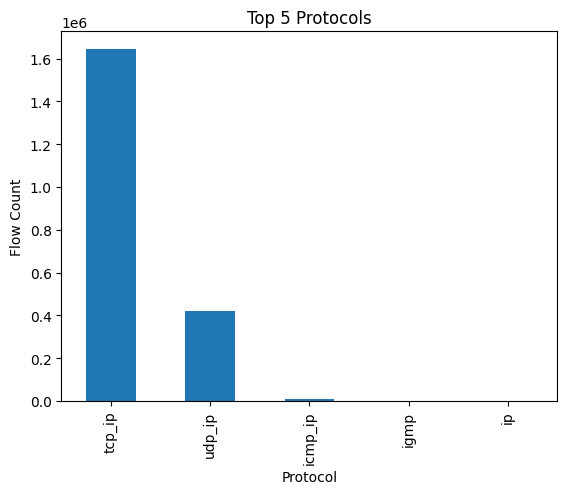

In [ ]:
import matplotlib.pyplot as plt

plt.figure()
top_protocols.plot(kind='bar')
plt.title("Top 5 Protocols")
plt.xlabel("Protocol")
plt.ylabel("Flow Count")
plt.show()

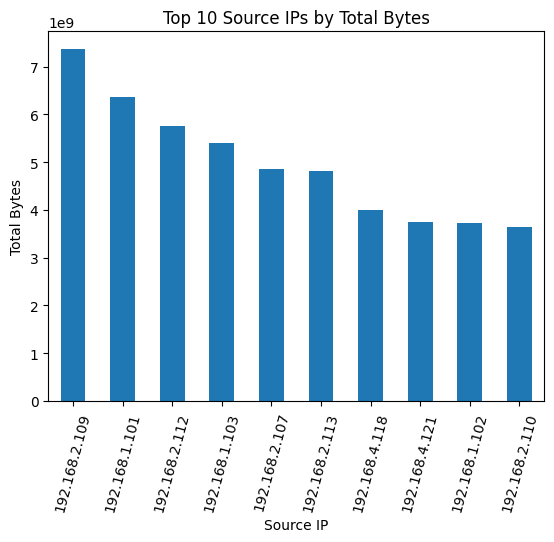

In [ ]:
plt.figure()
top_src_bytes.plot(kind='bar')
plt.title("Top 10 Source IPs by Total Bytes")
plt.xlabel("Source IP")
plt.ylabel("Total Bytes")
plt.xticks(rotation=75)
plt.show()

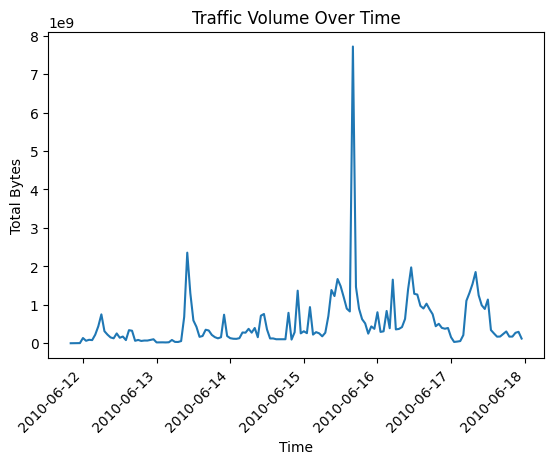

In [ ]:
plt.figure()
hourly_traffic.plot()
plt.title("Traffic Volume Over Time")
plt.xlabel("Time")
plt.ylabel("Total Bytes")
plt.xticks(rotation=45)
plt.show()

### Observations from Basic Traffic Statistics

- The dataset contains a large number of network flows, indicating substantial network activity.
- TCP traffic dominates the dataset, followed by UDP.
- A small number of IP addresses account for a large share of total traffic.
- Packet sizes show variability, suggesting a mix of different traffic types.
- Some IP addresses appear consistently across many hourly windows, indicating persistent communication behavior.
- A few time windows exhibit unusually high traffic volume and may require further investigation in later sections.

# Part - 2
## Traffic Estimation Using Sublinear Space

In [ ]:
## we will be trying to implement and compare both the exact and approximate approaches

## parts

### Estimating the Number of Unique IP address

Two approaches are used:

1. **Exact method** using a Python set  
2. **Approximate method**

The accuracy of the approximation is evaluated by comparing it with the exact count.

In [ ]:
import hashlib
import numpy as np
import math

# bitmap size (you can tune this)
m = 200000

bitmap = np.zeros(m)

def get_hash(x):
    return int(hashlib.md5(x.encode()).hexdigest(), 16) % m

# insert all IPs into bitmap
for ip in pd.concat([df['source'], df['destination']]).astype(str):
    idx = get_hash(ip)
    bitmap[idx] = 1

# count empty positions
V = np.sum(bitmap == 0)

# estimate unique count
estimated_unique_ips = -m * math.log(V / m)

# Calculate exact unique IPs
exact_unique_ips = len(set(df['source']).union(set(df['destination'])))

print("Exact unique IPs:", exact_unique_ips)
print("Estimated unique IPs:", int(estimated_unique_ips))

error = abs(estimated_unique_ips - exact_unique_ips) / exact_unique_ips * 100
print("Error (%):", error)

Exact unique IPs: 34801
Estimated unique IPs: 34805
Error (%): 0.012102968217923412


**Trade-off Discussion:**  
The sublinear estimator provides a memory-efficient approximation of the number of distinct IP addresses without storing all IP strings explicitly. Increasing the sketch size improves accuracy but increases memory usage. In contrast, the exact set-based method is fully accurate but requires memory proportional to the number of distinct IPs.

### Identifying the frequently contacted destination IP's

exact vs approximate analysis

In [ ]:
# exact destination flow counts
exact_counts = df['destination'].value_counts()

# top 10 destinations
top_exact = exact_counts.head(10)

print("Top destination IPs (exact counts):\n")
print(top_exact)

Top destination IPs (exact counts):

destination
198.164.30.2       232409
192.168.5.122      199437
203.73.24.75       193200
125.6.164.51       106826
67.220.214.50       49298
202.210.143.140     36189
82.98.86.183        25214
95.211.98.12        25095
209.112.44.10       21824
62.140.213.243      20509
Name: count, dtype: int64


In [ ]:
total_flows = len(df)
threshold_fraction = 0.005   # 0.5%

heavy_hitter_threshold = total_flows * threshold_fraction

heavy_hitters_exact = exact_counts[exact_counts >= heavy_hitter_threshold]

print("Heavy hitter threshold (flows):", heavy_hitter_threshold)
print("\nExact heavy hitters:\n")
print(heavy_hitters_exact)

Heavy hitter threshold (flows): 10358.285

Exact heavy hitters:

destination
198.164.30.2       232409
192.168.5.122      199437
203.73.24.75       193200
125.6.164.51       106826
67.220.214.50       49298
202.210.143.140     36189
82.98.86.183        25214
95.211.98.12        25095
209.112.44.10       21824
62.140.213.243      20509
64.38.193.26        20015
67.111.12.102       19480
125.6.176.113       16434
91.190.170.71       15000
208.116.9.82        14725
95.211.98.14        12975
125.6.164.41        12242
192.168.2.255       12017
82.98.86.181        11476
Name: count, dtype: int64


In [ ]:
import numpy as np

# count-min sketch parameters
width = 3000
depth = 5

cms = np.zeros((depth, width), dtype=int)

def hash_with_seed(x, seed):
    return hash((x, seed)) % width

# update sketch
for ip in df['destination'].astype(str):
    for d in range(depth):
        idx = hash_with_seed(ip, d)
        cms[d][idx] += 1

In [ ]:
def estimate_count(ip):
    return min(cms[d][hash_with_seed(ip, d)] for d in range(depth))

In [ ]:
## comparison

approx_results = []

for ip, exact in top_exact.items():
    est = estimate_count(ip)
    err = abs(est - exact) / exact * 100

    approx_results.append([ip, exact, est, round(err, 3)])

approx_df = pd.DataFrame(approx_results, columns=['Destination IP', 'Exact Count', 'Estimated Count', 'Error %'])

approx_df

,Destination IP,Exact Count,Estimated Count,Error %
0,198.164.30.2,232409,232443,0.015
1,192.168.5.122,199437,199444,0.004
2,203.73.24.75,193200,193456,0.133
3,125.6.164.51,106826,106880,0.051
4,67.220.214.50,49298,49448,0.304
5,202.210.143.140,36189,36230,0.113
6,82.98.86.183,25214,25233,0.075
7,95.211.98.12,25095,25331,0.940
8,209.112.44.10,21824,22518,3.180
9,62.140.213.243,20509,20684,0.853


In [ ]:
max_error = approx_df['Error %'].max()
print("Maximum error among top destinations:", max_error, "%")

Maximum error among top destinations: 3.18 %


**Trade-off Discussion:**  
The Count-Min Sketch approximates destination frequencies using much less memory than exact per-IP counters. However, it may overestimate some counts due to hash collisions. Increasing the sketch width reduces estimation error, while increasing depth improves reliability at the cost of slightly more computation.

----

### part c - Efficient Membership Testing for blocklists

To test whether an IP address has been seen before, two approaches are used:

1. **Exact membership testing** using a Python set  
2. **Approximate membership testing** using a Bloom filter

Bloom filters are memory-efficient and fast, but they may produce false positives.

In [ ]:
# exact membership structure
exact_ip_set = set(df['source']).union(set(df['destination']))

print("Number of observed IPs:", len(exact_ip_set))

Number of observed IPs: 34801


In [ ]:
# bloom filter size
size = 500000
bit_array = np.zeros(size, dtype=int)

def h1(x):
    return hash(x) % size

def h2(x):
    return hash("salt_" + x) % size

def add_to_bloom(ip):
    bit_array[h1(ip)] = 1
    bit_array[h2(ip)] = 1

def check_bloom(ip):
    return bit_array[h1(ip)] == 1 and bit_array[h2(ip)] == 1

In [ ]:
for ip in exact_ip_set:
    add_to_bloom(str(ip))

print("Bloom filter built.")

Bloom filter built.


In [ ]:
false_negatives = 0

for ip in exact_ip_set:
    if not check_bloom(str(ip)):
        false_negatives += 1

print("False negatives:", false_negatives)

False negatives: 0


In [ ]:
false_positives = 0
tests = 5000

for i in range(tests):
    fake_ip = f"250.250.{i//256}.{i%256}"

    if fake_ip not in exact_ip_set and check_bloom(fake_ip):
        false_positives += 1

fp_rate = false_positives / tests * 100

print("False positives:", false_positives)
print("False positive rate (%):", fp_rate)

False positives: 86
False positive rate (%): 1.72


**Trade-off :**  
The Bloom filter provides fast and memory-efficient membership testing with no false negatives, but it may return false positives.
Increasing the filter size reduces the false positive rate, while adding more hash functions can improve or worsen performance depending on the configuration.

### 2) Final Observations and Trade-offs

- The bitmap-based estimator produced a very accurate approximation of the number of unique IP addresses while using fixed memory.
- Count-Min Sketch was able to approximate destination IP frequencies effectively, especially for the most frequent destinations.
- Bloom filter membership testing was highly space-efficient and produced no false negatives, with only a small false positive rate.
- These results show that approximate methods can provide useful traffic insights while using much less memory than exact full-data approaches.

In this notebook, a destination IP is treated as a heavy hitter if it accounts for at least **0.5% of total flows**.

---


# Part 3 - Advanced Anomaly Detection

In this section, the traffic data is analyzed to identify anomalous behavior using statistical, temporal, and behavioral methods. The goal is to detect unusual communication patterns that may indicate suspicious or malicious activity.

### 3.1 statistical traffic analysis

In [ ]:
# packet size thresholds
packet_mean = df['packet_size'].mean()
packet_std = df['packet_size'].std()

packet_low = max(packet_mean - 3 * packet_std, 0)
packet_high = packet_mean + 3 * packet_std

print("Packet size mean:", packet_mean)
print("Packet size std:", packet_std)
print("Low threshold:", packet_low)
print("High threshold:", packet_high)

Packet size mean: 315.78901161706864
Packet size std: 266.0748245125578
Low threshold: 0
High threshold: 1114.013485154742


In [ ]:
packet_anomalies = df[(df['packet_size'] < packet_low) | (df['packet_size'] > packet_high)]

print("Number of packet size anomalies:", len(packet_anomalies))
packet_anomalies[['source', 'destination', 'protocolName', 'packet_size', 'Label']].head(10)

Number of packet size anomalies: 48


,source,destination,protocolName,packet_size,Label
134951,192.168.2.110,192.168.5.122,tcp_ip,1132.401186,Normal
172089,192.168.2.108,192.168.5.122,tcp_ip,1128.518433,Normal
174204,192.168.5.122,198.164.30.2,udp_ip,1560.000000,Normal
174274,192.168.5.122,198.164.30.2,udp_ip,1402.500000,Normal
175671,192.168.5.122,198.164.30.2,udp_ip,1407.500000,Normal
176729,192.168.5.122,198.164.30.2,udp_ip,1560.000000,Normal
177762,192.168.5.122,198.164.30.2,udp_ip,1415.500000,Normal
177763,192.168.5.122,198.164.30.2,udp_ip,1403.500000,Normal
177775,192.168.5.122,198.164.30.2,udp_ip,1560.000000,Normal
177993,192.168.5.122,198.164.30.2,udp_ip,1237.500000,Normal


In [ ]:
## we would be analysing the flow count anomalies across diff time windows
## we would be comparing hourly vs daily


In [ ]:
# hourly flow count
hourly_flow_counts = df.groupby('hour').size()

hourly_std = hourly_flow_counts.std()
hourly_mean = hourly_flow_counts.mean()

hourly_high = hourly_mean + 3 * hourly_std
hourly_low = max(hourly_mean - 3 * hourly_std, 0)

print("Hourly flow count mean:", hourly_mean)
print("Hourly flow count std:", hourly_std)
print("Hourly anomaly threshold:", hourly_high)

Hourly flow count mean: 14189.431506849314
Hourly flow count std: 13113.637410598769
Hourly anomaly threshold: 53530.34373864562


In [ ]:
## detect hourly anomalies

hourly_anomalies = hourly_flow_counts[(hourly_flow_counts < hourly_low) | (hourly_flow_counts > hourly_high)]

print("Hourly flow anomalies:\n")
print(hourly_anomalies)

Hourly flow anomalies:

hour
2010-06-13 10:00:00    67952
2010-06-15 16:00:00    63821
dtype: int64


In [ ]:
## daily comparison

In [ ]:
df['day'] = df['startDateTime'].dt.date

daily_flow_counts = df.groupby('day').size()

daily_std = daily_flow_counts.std()
daily_mean = daily_flow_counts.mean()

daily_high = daily_mean + 2 * daily_std
daily_low = max(daily_mean - 2 * daily_std, 0)

daily_anomalies = daily_flow_counts[(daily_flow_counts < daily_low) | (daily_flow_counts > daily_high)]

print("Daily flow anomalies:\n")
print(daily_anomalies)

Daily flow anomalies:

Series([], dtype: int64)


In [ ]:
## the previous approach didn't find any good anomalies


#### Daily-Level Comparison

Although no strong anomalies were detected in daily flow counts alone, daily traffic is further compared using total bytes, protocol composition, and attack label distribution to identify broader deviations.

In [ ]:
daily_bytes = df.groupby('day')['total_bytes'].sum()

daily_bytes_mean = daily_bytes.mean()
daily_bytes_std = daily_bytes.std()

daily_bytes_high = daily_bytes_mean + 2 * daily_bytes_std
daily_bytes_low = max(daily_bytes_mean - 2 * daily_bytes_std, 0)

daily_byte_anomalies = daily_bytes[(daily_bytes < daily_bytes_low) | (daily_bytes > daily_bytes_high)]

print("Daily total bytes when thresholds are loose:\n")
print(daily_bytes)

print("\nDaily byte anomalies:\n")
if len(daily_byte_anomalies) == 0:
    print("No significant anomalies in daily byte volume.")
else:
    print(daily_byte_anomalies)


daily_bytes_high = daily_bytes_mean + 1 * daily_bytes_std
daily_bytes_low = max(daily_bytes_mean - 1 * daily_bytes_std, 0)

daily_byte_anomalies = daily_bytes[(daily_bytes < daily_bytes_low) | (daily_bytes > daily_bytes_high)]

print("\n\nDaily total bytes when thresholds are choosen agressively :\n")
print(daily_bytes)

print("\nDaily byte anomalies:\n")
if len(daily_byte_anomalies) == 0:
    print("No significant anomalies in daily byte volume.")
else:
    print(daily_byte_anomalies)

Daily total bytes when thresholds are loose:

day
2010-06-11        3554597
2010-06-12     4461319159
2010-06-13     8314101486
2010-06-14     7553049506
2010-06-15    24430508339
2010-06-16    18680993037
2010-06-17    13104314437
Name: total_bytes, dtype: int64

Daily byte anomalies:

No significant anomalies in daily byte volume.


Daily total bytes when thresholds are choosen agressively :

day
2010-06-11        3554597
2010-06-12     4461319159
2010-06-13     8314101486
2010-06-14     7553049506
2010-06-15    24430508339
2010-06-16    18680993037
2010-06-17    13104314437
Name: total_bytes, dtype: int64

Daily byte anomalies:

day
2010-06-11        3554597
2010-06-15    24430508339
Name: total_bytes, dtype: int64


Daily traffic was examined at two levels:

- **Strict anomaly detection** using wider thresholds for daily flow counts
- **More sensitive deviation analysis** using daily byte volume

This was done because daily aggregation can smooth out short-lived anomalies, making traffic volume and composition-based comparisons more informative than flow count alone.

No strong anomalies were detected at the daily flow-count level under the chosen threshold.
This suggests that anomalies in the dataset are more visible at finer temporal resolution (hourly) than when traffic is aggregated across entire days.

In [ ]:
# global protocol distribution
global_protocol_dist = df['protocolName'].value_counts(normalize=True)

protocol_deviation = []

for h, group in df.groupby('hour'):
    local_dist = group['protocolName'].value_counts(normalize=True)

    deviation = 0
    for proto in global_protocol_dist.index:
        deviation += abs(local_dist.get(proto, 0) - global_protocol_dist.get(proto, 0))

    protocol_deviation.append([h, deviation / 2, len(group)])

protocol_dev_df = pd.DataFrame(protocol_deviation, columns=['hour', 'deviation', 'flow_count'])
protocol_dev_df = protocol_dev_df.sort_values(by='deviation', ascending=False)

protocol_dev_df.head(10)

,hour,deviation,flow_count
72,2010-06-14 22:00:00,0.489948,7023
73,2010-06-14 23:00:00,0.457051,5793
71,2010-06-14 21:00:00,0.442293,4796
76,2010-06-15 02:00:00,0.408463,16680
78,2010-06-15 04:00:00,0.336081,17547
75,2010-06-15 01:00:00,0.334693,9859
77,2010-06-15 03:00:00,0.318610,14251
80,2010-06-15 06:00:00,0.316058,16612
79,2010-06-15 05:00:00,0.309543,16773
81,2010-06-15 07:00:00,0.287123,18386


The protocol distribution deviation measures how different a time window’s protocol mix is from the overall protocol distribution of the dataset.
Larger values indicate that a given hour contains an unusual balance of protocols compared to normal traffic behaviour.

In [ ]:
## combined IP volume analysis (source + destination)

src_bytes = df.groupby('source')['total_bytes'].sum().rename_axis('ip')
dst_bytes = df.groupby('destination')['total_bytes'].sum().rename_axis('ip')
ip_bytes = src_bytes.add(dst_bytes, fill_value=0)

ip_mean = ip_bytes.mean()
ip_std = ip_bytes.std()

ip_z = ((ip_bytes - ip_mean) / ip_std).sort_values(ascending=False)
high_volume_ips = ip_z.head(10)
low_volume_ips = ip_z.sort_values().head(10)

print('High volume IPs by z-score:\n')
print(pd.DataFrame({
    'total_bytes': ip_bytes.loc[high_volume_ips.index].astype('int64'),
    'z_score': high_volume_ips
}))

print('\nLowest volume IPs by z-score:\n')
print(pd.DataFrame({
    'total_bytes': ip_bytes.loc[low_volume_ips.index].astype('int64'),
    'z_score': low_volume_ips
}))

High volume IPs by z-score:

                total_bytes    z_score
ip                                    
192.168.5.122   12100525679  95.851928
192.168.2.109    7373568918  58.394654
192.168.1.101    6359182834  50.356473
192.168.2.112    5812627807  46.025470
69.84.133.138    5756927404  45.584090
192.168.1.103    5398389143  42.742967
192.168.2.107    4867563380  38.536606
192.168.2.113    4832321086  38.257340
192.168.4.118    4007791685  31.723618
95.154.240.242   3989071044  31.575272

Lowest volume IPs by z-score:

                 total_bytes   z_score
ip                                    
113.163.187.98            64 -0.034859
192.168.3.74              64 -0.034859
192.168.3.76              64 -0.034859
65.54.81.4                64 -0.034859
192.168.3.75              64 -0.034859
200.1.111.246             74 -0.034859
78.24.24.251              74 -0.034859
142.166.209.194           74 -0.034859
89.31.118.70              74 -0.034859
200.216.136.218           74 -0.034859


#### 3.2 - Behavioural Analysis

focuses on how traffic patterns evolve over time. Sudden activity changes, coordinated targeting, and large fan-in behavior can indicate scanning, coordinated attacks, or unusual communication bursts.

A source IP is flagged for sudden behavioural change if it remains relatively quiet for multiple time windows and then exhibits a sharp increase in hourly flow count compared to its typical activity.

A 1-hour window is used here as the definition of a “short time interval,” as it is fine-grained enough to capture coordinated bursts without becoming too noisy.

In [ ]:
# flow counts per source IP per hour
ip_hourly = df.groupby(['source', 'hour']).size().reset_index(name='flow_count')

sudden_change = []

for ip, group in ip_hourly.groupby('source'):
    counts = group['flow_count']

    if len(counts) < 5:
        continue

    avg = counts.mean()
    mx = counts.max()
    inactive = (counts <= 2).sum()

    if inactive >= 2 and mx > 5 * (avg + 1):
        sudden_change.append([ip, avg, mx, inactive])

sudden_change_df = pd.DataFrame(sudden_change, columns=['IP', 'Avg Hourly Flows', 'Max Hourly Flows', 'Inactive Windows'])
sudden_change_df = sudden_change_df.sort_values(by='Max Hourly Flows', ascending=False)

sudden_change_df.head(10)

,IP,Avg Hourly Flows,Max Hourly Flows,Inactive Windows
3,192.168.4.121,830.346457,7498,2
1,131.202.243.90,435.250000,5116,6
2,192.168.3.117,198.958333,1715,4
4,192.168.5.124,131.916667,1177,9
0,131.202.240.209,15.242857,491,16
5,210.172.144.10,4.700000,32,14


In [ ]:
target_sources = df.groupby(['hour', 'destination'])['source'].nunique().reset_index(name='distinct_sources')

coordinated_targets = target_sources[target_sources['distinct_sources'] >= 20].sort_values(by='distinct_sources', ascending=False)

coordinated_targets.head(10)

,hour,destination,distinct_sources
63171,2010-06-15 07:00:00,192.168.2.107,468
43021,2010-06-15 02:00:00,192.168.2.107,467
50913,2010-06-15 04:00:00,192.168.2.107,436
59026,2010-06-15 06:00:00,192.168.2.107,426
55019,2010-06-15 05:00:00,192.168.2.107,411
47109,2010-06-15 03:00:00,192.168.2.107,394
67501,2010-06-15 08:00:00,192.168.2.107,388
39483,2010-06-15 01:00:00,192.168.2.107,305
31403,2010-06-14 22:00:00,192.168.2.107,183
34175,2010-06-14 23:00:00,192.168.2.107,153


#### 3.3 Suspicious Communication Patterns

communication patterns may indicate suspicious activity, including unusually long-lived connections and IPs using multiple protocols within a short time period.

In [ ]:
duration_mean = df['duration_seconds'].mean()
duration_std = df['duration_seconds'].std()

duration_threshold = duration_mean + 3 * duration_std

print("Long duration threshold:", duration_threshold)

Long duration threshold: 1908.294860434319


In [ ]:
long_flows = df[df['duration_seconds'] > duration_threshold]

print("Number of long-duration flows:", len(long_flows))

long_flows[['source', 'destination', 'protocolName', 'duration_seconds', 'Label']].sort_values(by='duration_seconds', ascending=False).head(10)

Number of long-duration flows: 7628


,source,destination,protocolName,duration_seconds,Label
915865,192.168.1.101,192.168.1.255,udp_ip,49140.0,Normal
915864,192.168.1.101,255.255.255.255,udp_ip,49140.0,Normal
915866,192.168.2.109,255.255.255.255,udp_ip,48960.0,Normal
915867,192.168.2.109,192.168.2.255,udp_ip,48960.0,Normal
915870,192.168.2.112,192.168.2.109,tcp_ip,48900.0,Normal
915869,192.168.2.112,192.168.2.255,udp_ip,48900.0,Normal
915868,192.168.2.112,255.255.255.255,udp_ip,48900.0,Normal
915873,192.168.3.117,255.255.255.255,udp_ip,48780.0,Normal
915874,192.168.3.117,192.168.3.255,udp_ip,48780.0,Normal
915872,192.168.3.114,192.168.3.255,udp_ip,48780.0,Normal


In [ ]:
## now to flag the IPs , assume that if an IP uses 3 or more protocols in one hour then flag it

In [ ]:
multi_proto = df.groupby(['source', 'hour'])['protocolName'].nunique().reset_index(name='protocol_count')

multi_proto_ips = multi_proto[multi_proto['protocol_count'] >= 3].sort_values(by='protocol_count', ascending=False)

multi_proto_ips.head(10)

,source,hour,protocol_count
2345,192.168.2.107,2010-06-14 21:00:00,4
3,0.0.0.0,2010-06-12 03:00:00,3
2013,192.168.1.105,2010-06-13 09:00:00,3
1434,192.168.1.101,2010-06-13 10:00:00,3
2020,192.168.1.105,2010-06-13 16:00:00,3
2279,192.168.2.107,2010-06-12 03:00:00,3
2309,192.168.2.107,2010-06-13 09:00:00,3
2357,192.168.2.107,2010-06-15 09:00:00,3
3041,192.168.2.112,2010-06-13 16:00:00,3
3066,192.168.2.112,2010-06-14 17:00:00,3


### 3.4 Observations

- Packet size outliers indicate unusually small or large traffic flows compared to the dataset average.
- Some hourly and daily windows show abnormal traffic volume, suggesting temporal anomalies.
- Certain source IPs exhibit unusually high traffic volume relative to others.
- A few IPs show sudden bursts in activity after relatively quiet periods, which may indicate suspicious behavior.
- Some destination IPs receive traffic from many distinct sources in the same time window, which may suggest coordinated access or attack-like behavior.
- A subset of flows remains active for significantly longer than normal.
- Multi-protocol communication in short time windows may indicate scanning or exploratory behavior.

## 4. Deep Security Threat Analysis

In this section, the network traffic is examined for deeper security-relevant patterns that may indicate coordinated attacks, stealthy probing, suspicious communication behavior, or encrypted traffic irregularities.

The goal is not to prove compromise with certainty, but to identify **strong candidates for suspicious or malicious behavior** based on observable traffic patterns.

### 4.1 Detection of Complex Attack Patterns

This subsection identifies stealthy and coordinated attack-like behavior using port access patterns, distributed source behavior, and source rotation.

In [ ]:
# summarize source behavior
scan_features = df.groupby('source').agg(
    unique_ports=('destinationPort', 'nunique'),
    unique_destinations=('destination', 'nunique'),
    active_hours=('hour', 'nunique'),
    avg_bytes=('total_bytes', 'mean'),
    total_flows=('destinationPort', 'count')
)

scan_features = scan_features.sort_values(by='unique_ports', ascending=False)
scan_features.head(10)

,unique_ports,unique_destinations,active_hours,avg_bytes,total_flows
source,,,,,
192.168.2.107,16961,23744,145,23328.140945,208379
192.168.4.121,3668,2138,127,35558.480390,105454
192.168.1.105,1610,1979,145,34116.689431,101359
192.168.2.112,1150,1849,145,65229.346372,88301
192.168.4.118,647,1927,145,29593.055934,135374
192.168.3.114,597,1633,145,46289.029575,55588
192.168.2.113,572,1806,145,62137.866775,77433
192.168.2.111,535,1323,145,34287.648323,61491
192.168.1.104,396,1448,145,29516.229449,65666


In [ ]:
stealth_scan_candidates = scan_features[
    (scan_features['unique_ports'] >= 50) &
    (scan_features['unique_destinations'] <= 20) &
    (scan_features['avg_bytes'] <= 2000) &
    (scan_features['active_hours'] >= 4)
].sort_values(by='unique_ports', ascending=False)

stealth_scan_candidates.head(10)

,unique_ports,unique_destinations,active_hours,avg_bytes,total_flows
source,,,,,


In [ ]:
repeat_summary = df.groupby(['source', 'destinationPort']).size().groupby('source').max()

stealth_scan_candidates = stealth_scan_candidates.join(repeat_summary.rename('max_repeats_per_port'))

stealth_scan_candidates = stealth_scan_candidates[
    stealth_scan_candidates['max_repeats_per_port'] <= 3
].sort_values(by='unique_ports', ascending=False)

stealth_scan_candidates.head(10)

,unique_ports,unique_destinations,active_hours,avg_bytes,total_flows,max_repeats_per_port
source,,,,,,


#### Stealth Scan Interpretation Note

The stricter stealth-scan rule above returned no strong candidates. That is an important result in itself: it suggests the dataset is not dominated by classic low-and-slow broad port scanning under the chosen definition.

A looser port-diversity heuristic is explored next, but its outputs should be treated as **scan-like candidates only**, not as confirmed stealth scans.

In [ ]:
scan_features = df.groupby('source').agg(
    unique_ports=('destinationPort', 'nunique'),
    total_flows=('destinationPort', 'count'),
    active_hours=('hour', 'nunique'),
    avg_bytes=('total_bytes', 'mean')
)

# ratio of unique ports to total flows
scan_features['port_diversity_ratio'] = scan_features['unique_ports'] / scan_features['total_flows']

scan_features = scan_features.sort_values(by='unique_ports', ascending=False)
scan_features.head(10)

,unique_ports,total_flows,active_hours,avg_bytes,port_diversity_ratio
source,,,,,
192.168.2.107,16961,208379,145,23328.140945,0.081395
192.168.4.121,3668,105454,127,35558.480390,0.034783
192.168.1.105,1610,101359,145,34116.689431,0.015884
192.168.2.112,1150,88301,145,65229.346372,0.013024
192.168.4.118,647,135374,145,29593.055934,0.004779
192.168.3.114,597,55588,145,46289.029575,0.010740
192.168.2.113,572,77433,145,62137.866775,0.007387
192.168.2.111,535,61491,145,34287.648323,0.008700
192.168.1.104,396,65666,145,29516.229449,0.006031


In [ ]:
stealth_scan_candidates = scan_features[
    (scan_features['unique_ports'] >= 50) &
    (scan_features['active_hours'] >= 4) &
    (scan_features['port_diversity_ratio'] >= 0.01)
].sort_values(by='unique_ports', ascending=False)

stealth_scan_candidates.head(10)

,unique_ports,total_flows,active_hours,avg_bytes,port_diversity_ratio
source,,,,,
192.168.2.107,16961,208379,145,23328.140945,0.081395
192.168.4.121,3668,105454,127,35558.480390,0.034783
192.168.1.105,1610,101359,145,34116.689431,0.015884
192.168.2.112,1150,88301,145,65229.346372,0.013024
192.168.3.114,597,55588,145,46289.029575,0.010740


#### Slow DDoS / Sustained Distributed Pressure

A destination may experience slow distributed pressure when it is contacted by many distinct source IPs over multiple time windows, even if no single hour shows a dramatic spike.

To capture this, the number of distinct sources contacting each destination is tracked over time.|

In [ ]:
dest_hour_sources = df.groupby(['destination', 'hour'])['source'].nunique().reset_index(name='distinct_sources')

ddos_summary = dest_hour_sources.groupby('destination').agg(
    avg_distinct_sources=('distinct_sources', 'mean'),
    max_distinct_sources=('distinct_sources', 'max'),
    active_hours=('hour', 'nunique')
)

slow_ddos_candidates = ddos_summary[
    (ddos_summary['avg_distinct_sources'] >= 5) &
    (ddos_summary['max_distinct_sources'] >= 20) &
    (ddos_summary['active_hours'] >= 4)
].sort_values(by='max_distinct_sources', ascending=False)

slow_ddos_candidates.head(10)

,avg_distinct_sources,max_distinct_sources,active_hours
destination,,,
192.168.2.107,28.402778,468,144
192.168.5.122,23.027586,38,145


**Observation:**  
Destination 192.168.2.107 shows strong evidence of sustained distributed pressure, with up to 468 distinct sources in a single hour and continuous activity across 144 hours. This pattern is consistent with slow DDoS-like behavior.

In contrast, 192.168.5.122 shows moderate multi-source activity but with significantly lower peak intensity.

#### IP Hopping / Rotating Source Behaviour

This analysis identifies destination IPs that are repeatedly contacted by many different source IPs. Such patterns may reflect distributed access, source rotation, or hopping-style communication.

- Direct attacker attribution is not possible from flow logs alone.
Therefore, “IP hopping” is treated here as a heuristic pattern where a destination is contacted by a large and rotating set of source IPs over time, which may indicate evasion or distributed access behaviour.

In [ ]:
ip_hopping = df.groupby('destination').agg(
    distinct_sources=('source', 'nunique'),
    total_flows=('source', 'count'),
    active_hours=('hour', 'nunique'),
    protocol_count=('protocolName', 'nunique')
)

ip_hopping['source_diversity_ratio'] = ip_hopping['distinct_sources'] / ip_hopping['total_flows']

ip_hopping_candidates = ip_hopping[
    (ip_hopping['distinct_sources'] >= 20) &
    (ip_hopping['active_hours'] >= 4)
].sort_values(by='distinct_sources', ascending=False)

ip_hopping_candidates.head(10)

,distinct_sources,total_flows,active_hours,protocol_count,source_diversity_ratio
destination,,,,,
192.168.2.107,2345,6802,144,3,0.344752
192.168.5.122,104,199437,145,3,0.000521
64.95.64.198,22,613,119,2,0.035889
67.220.214.51,22,1890,77,2,0.011640
211.233.19.78,22,1164,85,2,0.018900
72.14.204.99,22,1411,116,2,0.015592
128.121.66.251,21,524,71,1,0.040076
128.242.240.116,21,295,60,1,0.071186
128.242.240.148,21,415,68,1,0.050602


**Observation:**  
Destination 192.168.2.107 exhibits extremely high source diversity, with 2345 distinct source IPs contributing to a relatively small number of flows. This suggests a rotating or distributed communication pattern, reinforcing its classification as a high-risk candidate.

Other destinations show much lower diversity ratios, indicating more stable and repeated communication patterns.

#### Encrypted Traffic Irregularities

Encrypted-looking traffic is identified based on common secure web indicators such as application name and destination port. Flows with unusually high byte volume or long duration are treated as suspicious candidates for further inspection.

In [ ]:
encrypted_df = df[
    (df['appName'].isin(['SecureWeb', 'Unknown_TCP'])) |
    (df['destinationPort'].isin([443, 8443]))
].copy()

print("Encrypted-looking flows:", len(encrypted_df))

Encrypted-looking flows: 85785


In [ ]:
enc_byte_mean = encrypted_df['total_bytes'].mean()
enc_byte_std = encrypted_df['total_bytes'].std()

enc_dur_mean = encrypted_df['duration_seconds'].mean()
enc_dur_std = encrypted_df['duration_seconds'].std()

byte_threshold = enc_byte_mean + 3 * enc_byte_std
dur_threshold = enc_dur_mean + 3 * enc_dur_std

print("Encrypted byte threshold:", byte_threshold)
print("Encrypted duration threshold:", dur_threshold)

Encrypted byte threshold: 994294.46017901
Encrypted duration threshold: 5770.6216259363255


In [ ]:
encrypted_anomalies = encrypted_df[
    (encrypted_df['total_bytes'] > byte_threshold) |
    (encrypted_df['duration_seconds'] > dur_threshold)
].sort_values(by='total_bytes', ascending=False)

encrypted_anomalies[['source', 'destination', 'destinationPort', 'appName', 'total_bytes', 'duration_seconds', 'Label']].head(10)

,source,destination,destinationPort,appName,total_bytes,duration_seconds,Label
504102,192.168.1.105,131.202.243.90,5555,SecureWeb,48082183,12720.0,Attack
504101,192.168.1.105,131.202.243.90,5555,SecureWeb,48082183,12720.0,Attack
138192,192.168.2.112,131.202.243.84,5555,SecureWeb,27584342,5220.0,Attack
530331,192.168.1.105,192.168.2.112,4444,Unknown_TCP,24223254,4980.0,Attack
530336,192.168.1.105,192.168.2.112,4444,Unknown_TCP,24223254,4980.0,Attack
524271,192.168.2.112,131.202.243.90,5555,SecureWeb,16333335,15120.0,Attack
524272,192.168.2.112,131.202.243.90,5555,SecureWeb,16333335,15120.0,Attack
159540,192.168.2.107,109.86.25.208,48412,Unknown_TCP,12888748,6900.0,Normal
977710,192.168.2.107,109.86.25.208,48412,Unknown_TCP,12137496,13860.0,Normal
159436,192.168.2.107,77.41.70.224,27571,Unknown_TCP,10648704,6960.0,Normal


#### Payload Heuristics and C2-like Patterns

The assignment also asks for malicious payload identification and C2-like communication patterns. Since we only have flow-level payload text fragments, this analysis is heuristic rather than signature-perfect.

The rules below look for:
- unusual text tokens in payload fragments
- repeated keyword-bearing flows between the same source-destination pair
- context, so that clearly benign web/CDN references are described more cautiously


In [ ]:
payload_keywords = ['cmd', 'irc', 'bot', 'doubleclick', 'amazon', 'imdb']
benign_like_patterns = ['amazon', 'doubleclick', 'imdb', 'google', 'youtube', 'facebook', 'cdn']

payload_text = (
    df['sourcePayloadAsUTF'].fillna('').astype(str) + ' ' +
    df['destinationPayloadAsUTF'].fillna('').astype(str)
).str.strip()

payload_base = df.loc[payload_text != '', ['source', 'destination', 'protocolName', 'appName', 'Label']].copy()
payload_base['payload_text'] = payload_text[payload_text != '']
lowered = payload_base['payload_text'].str.lower()

keyword_masks = {kw: lowered.str.contains(kw, regex=False) for kw in payload_keywords}
keyword_match_mask = pd.DataFrame(keyword_masks).any(axis=1)
payload_df = payload_base.loc[keyword_match_mask].copy()

payload_df['keyword_hits'] = payload_df.index.to_series().apply(
    lambda idx: ', '.join([kw for kw in payload_keywords if bool(keyword_masks[kw].loc[idx])])
)
payload_df['benign_like'] = payload_df['payload_text'].str.contains('|'.join(benign_like_patterns), case=False, regex=True)
payload_df['preview'] = payload_df['payload_text'].str[:160]
payload_df = payload_df.drop(columns=['payload_text'])

payload_df.head(10)


,source,destination,protocolName,appName,Label,keyword_hits,benign_like,preview
1003,192.168.4.121,192.168.5.122,udp_ip,DNS,Normal,amazon,True,.{.......amazon.com......<.H.......<........
1004,192.168.5.122,198.164.30.2,udp_ip,DNS,Normal,amazon,True,u.......amazon.com......<.H..A....<........
1009,192.168.4.121,192.168.5.122,udp_ip,DNS,Normal,amazon,True,",e.......www.amazon.com......<.H........+.ns-"
1012,192.168.5.122,198.164.30.2,udp_ip,DNS,Normal,amazon,True,2:.......www.amazon.com......<.H........+.ns-
1016,192.168.5.122,198.164.30.2,udp_ip,DNS,Normal,amazon,True,C.......g-ecximages-amazon.com......<).g-ecximag
1017,192.168.5.122,198.164.30.2,udp_ip,DNS,Normal,amazon,True,J........g-ecximages-amazon.com.cfootprint.net...
1018,192.168.4.121,192.168.5.122,udp_ip,DNS,Normal,amazon,True,.........g-ecximages-amazon.com......<).g-ecximag
1019,192.168.5.122,198.164.30.2,udp_ip,DNS,Normal,amazon,True,ecximages-amazoncom 'ecximages-a
1021,192.168.5.122,198.164.30.2,udp_ip,DNS,Normal,amazon,True,.........ecximages-amazon.com.cfootprint.net.....
1022,192.168.4.121,192.168.5.122,udp_ip,DNS,Normal,amazon,True,.........ecximages-amazon.com...... '.ecximages-a


In [ ]:
c2_signal_df = payload_df[~payload_df['benign_like']].copy()

if len(c2_signal_df) == 0:
    c2_like_pairs = pd.DataFrame(columns=['source', 'destination', 'repeated_indicators'])
else:
    c2_like_pairs = (c2_signal_df.groupby(['source', 'destination'])
                     .size()
                     .reset_index(name='repeated_indicators')
                     .sort_values(by='repeated_indicators', ascending=False))

print('Top repeated payload-indicator pairs (excluding clearly benign-like content):\n')
c2_like_pairs.head(10)

Top repeated payload-indicator pairs (excluding clearly benign-like content):



,source,destination,repeated_indicators
1213,192.168.2.112,69.84.133.138,425
100,192.168.1.101,67.111.12.102,399
1477,192.168.3.115,198.172.106.125,332
1052,192.168.2.111,198.172.106.125,238
1105,192.168.2.111,69.84.133.138,203
1648,192.168.3.116,74.54.152.11,201
973,192.168.2.110,209.62.20.192,195
1117,192.168.2.111,82.98.86.181,194
1228,192.168.2.112,82.98.86.181,194
356,192.168.1.103,74.54.152.11,193


#### Event-level Risk Classification

The assignment requires each detected security event to be labelled as **Low**, **Medium**, or **High** risk with justification. The table below consolidates the strongest findings from Part 4 into an explicit risk register.

To keep the conclusions defensible:
- `192.168.2.107` is treated as the strongest high-risk rotating-source target
- `192.168.5.122` is treated as medium risk because it is persistent but much less concentrated
- C2-like payload repetition is based only on payloads that are **not** clearly benign-like

In [ ]:
risk_events = []

if '192.168.2.107' in ip_hopping_candidates.index:
    row = ip_hopping_candidates.loc['192.168.2.107']
    risk_events.append({
        'event_type': 'IP hopping / rotating source behaviour',
        'subject': '192.168.2.107',
        'risk_level': 'High',
        'justification': f"{int(row['distinct_sources'])} distinct source IPs across {int(row['active_hours'])} active hours"
    })

if '192.168.5.122' in ip_hopping_candidates.index:
    row = ip_hopping_candidates.loc['192.168.5.122']
    risk_events.append({
        'event_type': 'IP hopping / rotating source behaviour',
        'subject': '192.168.5.122',
        'risk_level': 'Medium',
        'justification': f"{int(row['distinct_sources'])} distinct source IPs across {int(row['active_hours'])} active hours"
    })

for _, row in encrypted_anomalies.head(5).iterrows():
    risk = 'High' if (row['destinationPort'] in [4444, 5555] and row['Label'] == 'Attack') else 'Medium'
    risk_events.append({
        'event_type': 'Unusual encrypted traffic',
        'subject': f"{row['source']} -> {row['destination']}",
        'risk_level': risk,
        'justification': f"{int(row['total_bytes'])} bytes on port {int(row['destinationPort'])}, label={row['Label']}"
    })

for _, row in c2_like_pairs.head(3).iterrows():
    risk_events.append({
        'event_type': 'Potential C2-like repetition',
        'subject': f"{row['source']} -> {row['destination']}",
        'risk_level': 'Medium',
        'justification': f"Repeated non-benign payload indicator pattern observed {int(row['repeated_indicators'])} times"
    })

risk_df = pd.DataFrame(risk_events).drop_duplicates().reset_index(drop=True)
risk_df

,event_type,subject,risk_level,justification
0,IP hopping / rotating source behaviour,192.168.2.107,High,2345 distinct source IPs across 144 active hours
1,IP hopping / rotating source behaviour,192.168.5.122,Medium,104 distinct source IPs across 145 active hours
2,Unusual encrypted traffic,192.168.1.105 -> 131.202.243.90,High,"48082183 bytes on port 5555, label=Attack"
3,Unusual encrypted traffic,192.168.2.112 -> 131.202.243.84,High,"27584342 bytes on port 5555, label=Attack"
4,Unusual encrypted traffic,192.168.1.105 -> 192.168.2.112,High,"24223254 bytes on port 4444, label=Attack"
5,Potential C2-like repetition,192.168.2.112 -> 69.84.133.138,Medium,Repeated non-benign payload indicator pattern ...
6,Potential C2-like repetition,192.168.1.101 -> 67.111.12.102,Medium,Repeated non-benign payload indicator pattern ...
7,Potential C2-like repetition,192.168.3.115 -> 198.172.106.125,Medium,Repeated non-benign payload indicator pattern ...


**Observation:**
Several large and long-duration encrypted-like flows were identified on uncommon ports such as 4444 and 5555. These ports are not proof of malware by themselves, but they are sufficiently unusual to justify medium-to-high risk classification when combined with very large byte counts and `Attack` labels.

This section should therefore be read as **strong heuristic evidence**, not definitive attribution.

**Cross-Pattern Insight:**
The IP address `192.168.2.107` appears repeatedly in the strongest coordinated-targeting and rotating-source analyses. That repeated presence is a strong reason to prioritize it in the final report.

However, the notebook should not overclaim classic stealth scanning here, because the stricter stealth-scan detector did **not** return strong candidates.

### Final Threat Assessment

The most credible high-priority findings in this notebook are:

- destination `192.168.2.107`, which shows extremely high source diversity and sustained many-to-one pressure
- several very large encrypted-like flows on uncommon ports such as `4444` and `5555`, especially when the dataset label is `Attack`

Additional medium-risk findings include:

- destination `192.168.5.122`, which shows persistent rotating-source communication over a long span but much weaker concentration than `192.168.2.107`
- repeated non-benign payload-indicator pairs, which are suggestive but still heuristic

By contrast, classic stealth-scan evidence is weak under the stricter detector, so scan-like behaviour should be described cautiously as a heuristic rather than a confirmed conclusion.

### 4.4 Concise Risk Report

The strongest security concerns observed in the dataset are summarized below.

- **High Risk:**
  - Destination **192.168.2.107** due to sustained many-source targeting and extremely high source diversity.
  - Large encrypted-like flows on ports **4444** and **5555** when they also carry the dataset label **Attack**.

- **Medium Risk:**
  - Destination **192.168.5.122**, which shows persistent rotating-source communication but weaker concentration than `192.168.2.107`.
  - Repeated payload-indicator pairs that resemble C2-like repetition but are still heuristic.

- **Low Risk / Caution:**
  - Simple payload keyword matches on web or CDN traffic, because benign content can overlap with naive keyword rules.
  - Broad port diversity on its own, unless corroborated by low-and-slow scan behaviour and restricted target sets.